# Correlação não é causalidade

Este notebook simula dois cenários: (1) correlação criada por uma variável confundidora, sem efeito causal de X sobre Y; (2) um efeito causal real de X sobre Y, ainda misturado com confundimento.

A simulação serve para tornar visível a diferença entre associação observada e intervenção.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

SEED = 42
rng = np.random.default_rng(SEED)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Correlação sem causalidade

Grafo causal hipotético: X <- Z -> Y. Z influencia X e Y. Não existe seta X -> Y. Ainda assim, X e Y podem parecer associados.

In [2]:
n = 1000
z = rng.normal(0, 1, n)
epsilon_x = rng.normal(0, 1, n)
epsilon_y = rng.normal(0, 1, n)

x = z + epsilon_x
y = z + epsilon_y
df = pd.DataFrame({'Z_confundidor': z, 'X': x, 'Y': y})

cov_xy = np.cov(x, y, ddof=1)[0, 1]
corr_xy = np.corrcoef(x, y)[0, 1]
observational_slope = LinearRegression().fit(x.reshape(-1, 1), y).coef_[0]
adjusted_slope = LinearRegression().fit(df[['X', 'Z_confundidor']], y).coef_[0]

print(f'Covariância observada Cov(X,Y): {cov_xy:.3f}')
print(f'Correlação observada: {corr_xy:.3f}')
print(f'Inclinação Y ~ X: {observational_slope:.3f}')
print(f'Coeficiente de X em Y ~ X + Z: {adjusted_slope:.3f}')
print('Valor teórico esperado: correlação = 0.5 e efeito causal = 0.0')

Covariância observada Cov(X,Y): 0.974
Correlação observada: 0.480
Inclinação Y ~ X: 0.489
Coeficiente de X em Y ~ X + Z: -0.026
Valor teórico esperado: correlação = 0.5 e efeito causal = 0.0


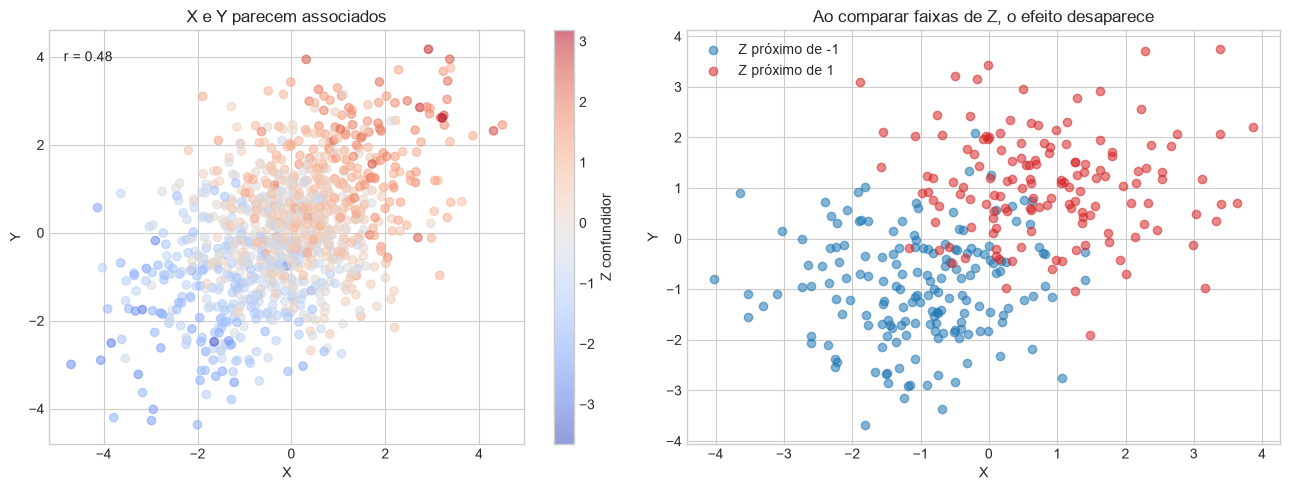

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
scatter = axes[0].scatter(df['X'], df['Y'], c=df['Z_confundidor'], cmap='coolwarm', alpha=0.55)
axes[0].set_title('X e Y parecem associados')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
axes[0].text(0.03, 0.95, f'r = {corr_xy:.2f}', transform=axes[0].transAxes, va='top')
fig.colorbar(scatter, ax=axes[0], label='Z confundidor')

for grupo, cor in [(-1, 'tab:blue'), (1, 'tab:red')]:
    mask = df['Z_confundidor'].between(grupo - 0.35, grupo + 0.35)
    axes[1].scatter(df.loc[mask, 'X'], df.loc[mask, 'Y'], alpha=0.55, label=f'Z próximo de {grupo}', color=cor)
axes[1].set_title('Ao comparar faixas de Z, o efeito desaparece')
axes[1].set_xlabel('X')
axes[1].set_ylabel('Y')
axes[1].legend()
plt.tight_layout()
plt.show()

### Conta do primeiro cenário

Como X = Z + epsilon_X e Y = Z + epsilon_Y, com variâncias unitárias e ruídos independentes:

- Cov(X,Y) = Var(Z) = 1;
- Var(X) = 2 e Var(Y) = 2;
- rho = 1 / (sqrt(2) * sqrt(2)) = 0.5;
- E[Y | do(X=x)] = 0, portanto o efeito causal é 0.

O ajuste por Z bloqueia o caminho X <- Z -> Y e faz o coeficiente de X se aproximar de zero.

## 2. Efeito causal real com confundimento

Agora definimos X = Z + epsilon_X e Y = 2X + Z + epsilon_Y. Existe um efeito causal direto de X sobre Y igual a 2. Porém Z também afeta X e Y. A regressão simples mistura os dois caminhos.

In [4]:
z2 = rng.normal(0, 1, n)
eps_x2 = rng.normal(0, 1, n)
eps_y2 = rng.normal(0, 1, n)
x2 = z2 + eps_x2
y2 = 2 * x2 + z2 + eps_y2

naive = LinearRegression().fit(x2.reshape(-1, 1), y2)
adjusted = LinearRegression().fit(np.column_stack([x2, z2]), y2)
print(f'Inclinação sem ajuste: {naive.coef_[0]:.3f}')
print(f'Coeficiente de X ajustando por Z: {adjusted.coef_[0]:.3f}')
print('Efeito causal definido na simulação: 2.0')
print('O ajuste recupera aproximadamente 2 porque conhecemos e medimos o confundidor Z.')

Inclinação sem ajuste: 2.524
Coeficiente de X ajustando por Z: 2.014
Efeito causal definido na simulação: 2.0
O ajuste recupera aproximadamente 2 porque conhecemos e medimos o confundidor Z.


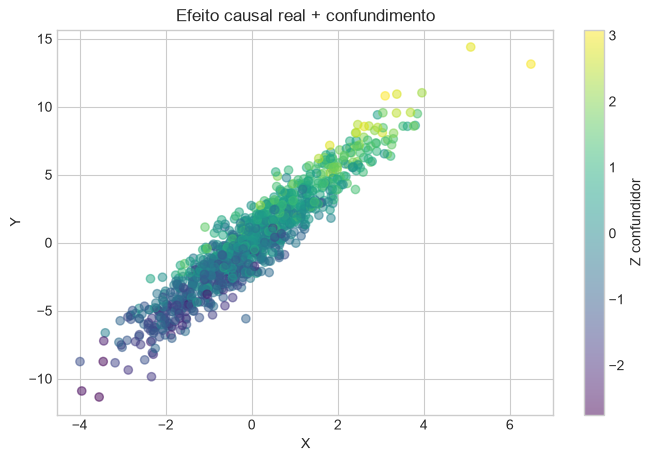

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(x2, y2, c=z2, cmap='viridis', alpha=0.5)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Efeito causal real + confundimento')
plt.colorbar(label='Z confundidor')
plt.show()

## 3. Tradução para Machine Learning

- Um heatmap mostra associação na amostra; não estabelece intervenção.
- Para previsão, uma feature pode ser útil mesmo sem ser causa.
- Para uma decisão como “o que acontece se eu mudar X?”, precisamos de hipóteses causais, desenho de estudo e ajuste adequado.
- A fórmula de ajuste, para confundidores discretos válidos, é E[Y | do(X=x)] = sum_z E[Y | X=x, Z=z] P(Z=z).

O ajuste só é válido sob hipóteses como ausência de confundidores não medidos, consistência e positividade.